# 🌳 Decision Tree — Classification, Regression & Model Evaluation

**Sinh viên:** Ngô Lâm Tiên  
**MSSV:** 524H0195  

---

## 🎯 Báo cáo Bài tập (Homework: Decision Tree)

Bài làm giải quyết trọn vẹn và chi tiết 3 nội dung yêu cầu của đề bài:

1. **Tìm hiểu Overfitting trong Decision Tree và cách giải quyết:**
   - Bản chất hiện tượng Overfitting (Low Bias, High Variance).
   - Các phương pháp giải quyết: **Pre-pruning** (`max_depth`, `min_samples_leaf`...), **Post-pruning** (Cost-Complexity Pruning `ccp_alpha`), **Ensemble Methods** (Random Forest, Boosting), và **Cross-Validation**.
   - Thực nghiệm trực quan hóa Overfitting & đường cong tỉa cành (Cost-Complexity Pruning curve).

2. **Code thực nghiệm Decision Tree cho Classification & Regression, so sánh với các phương pháp khác:**
   - **Classification (Iris & Titanic):** So sánh Decision Tree với **kNN, Logistic Regression, Random Forest** về Accuracy, Precision, Recall, F1-score và Confusion Matrix.
   - **Regression (Housing Price):** So sánh Decision Tree với **Linear Regression, kNN Regressor, Random Forest** về $R^2$ Score, RMSE, MAE và phân phối Residual.

3. **Ngoài Information Gain, các cách và độ đo khác để xây dựng Decision Tree:**
   - **Classification:** Gini Impurity (CART), Information Gain Ratio (C4.5), Chi-Square $\chi^2$ (CHAID), Twoing Criterion.
   - **Regression:** Variance Reduction / Mean Squared Error (MSE), Mean Absolute Error (MAE), Friedman MSE.
   - Bảng so sánh tổng hợp các họ thuật toán cây: **ID3, C4.5, CART, CHAID, C5.0**.

---
## 📖 Phần A — Lý thuyết Chuyên sâu: Decision Tree

### A.1 Câu hỏi 3: Ngoài Information Gain, còn những cách và độ đo nào khác để xây dựng Decision Tree?

#### 1. Tại sao không chỉ dùng Information Gain (ID3)?
Thuật toán **ID3** dùng **Information Gain** dựa trên Entropy:
$$H(D) = -\sum_{i=1}^{C} p_i \log_2(p_i)$$
$$IG(D, A) = H(D) - \sum_{v \in Values(A)} \frac{|D_v|}{|D|} H(D_v)$$
> ⚠️ **Nhược điểm chí mạng của Information Gain:** Có xu hướng **thiên vị cực đoan** các thuộc tính có nhiều giá trị riêng biệt (ví dụ: `ID_sinh_vien`, `So_dien_thoai`, `Ngay_sinh`). Khi tách theo thuộc tính này, mỗi nhánh chỉ chứa 1 mẫu nên $H(D_v) = 0$, dẫn đến $IG$ đạt giá trị tối đa nhưng mô hình bị quá khớp hoàn toàn và không có khả năng dự đoán mẫu mới.

#### 2. Các độ đo phân chia khác cho bài toán Phân loại (Classification):

| Độ đo | Thuật toán đại diện | Công thức toán học | Đặc điểm & Ưu điểm |
|---|---|---|---|
| **Gini Impurity** | **CART** (scikit-learn mặc định) | $Gini(D) = 1 - \sum_{i=1}^{C} p_i^2$ | Đo xác suất 1 phần tử bị gán nhãn sai ngẫu nhiên. **Không tính $\log_2$** nên tốc độ tính toán nhanh hơn Entropy vượt trội. |
| **Gain Ratio** | **C4.5 / C5.0** (Ross Quinlan) | $GainRatio = \frac{IG(D, A)}{SplitInfo_A(D)}$ với $SplitInfo = -\sum \frac{|D_v|}{|D|} \log_2\frac{|D_v|}{|D|}$ | Chuẩn hóa $IG$ bằng độ phức tạp phân chia $SplitInfo$, **triệt tiêu hoàn toàn sự thiên vị** của thuộc tính nhiều giá trị. |
| **Chi-Square $\chi^2$** | **CHAID** | $\chi^2 = \sum \frac{(O - E)^2}{E}$ ($O$: quan sát, $E$: kỳ vọng) | Sử dụng kiểm định giả thuyết thống kê; nếu sự khác biệt không có ý nghĩa thống kê ($p > \alpha$), thuật toán sẽ dừng không phân chia. |
| **Twoing Criterion** | **CART** (cho multi-class) | $Twoing(s) = \frac{|D_L||D_R|}{4|D|^2} \left( \sum |p(C_i|D_L) - p(C_i|D_R)| \right)^2$ | Tạm thời gộp các lớp thành 2 siêu lớp tối ưu để tìm điểm split nhị phân cân đối nhất. |

#### 3. Các độ đo phân chia cho bài toán Hồi quy (Regression):

| Độ đo | Công thức | Dự đoán tại lá | Đặc điểm |
|---|---|---|---|
| **Variance Reduction / MSE** | $MSE = \frac{1}{|D|}\sum_{i \in D} (y_i - \bar{y})^2$ | Trung bình $\bar{y}$ | Cực tiểu hóa tổng bình phương sai số của các node con. |
| **Mean Absolute Error (MAE)** | $MAE = \frac{1}{|D|}\sum_{i \in D} |y_i - \text{median}(y)|$ | Trung vị (Median) | Dùng hàm khoảng cách L1, **chống chịu tốt với dữ liệu ngoại lai (outliers)**. |
| **Friedman MSE** | $\text{Score} = \frac{|D_L||D_R|}{|D_L|+|D_R|} (\bar{y}_L - \bar{y}_R)^2$ | Trung bình $\bar{y}$ | Biến thể cải tiến của Jerome Friedman, tối ưu hóa cho bài toán Boosting/Ensemble. |

#### 4. Bảng tổng hợp so sánh các họ thuật toán cây quyết định:
| Tiêu chí | ID3 (1986) | C4.5 (1993) | CART (1984) | CHAID (1980) |
|---|---|---|---|---|
| **Tác giả** | Ross Quinlan | Ross Quinlan | Breiman, Friedman, Olshen, Stone | Gordon Kass |
| **Bài toán** | Phân loại | Phân loại | Phân loại & Hồi quy | Phân loại & Hồi quy |
| **Độ đo** | Information Gain | Gain Ratio | Gini (Clf), MSE/MAE (Reg) | Chi-Square $\chi^2$ |
| **Kiểu nhánh** | Đa nhánh (Multi-way) | Đa nhánh / Nhị phân | **Nhị phân nghiêm ngặt (Binary)** | Đa nhánh (Multi-way) |
| **Xử lý missing** | ❌ Không | ✅ Có (phân phối xác suất) | ✅ Có (Surrogate splits) | ✅ Coi missing là 1 nhóm |
| **Tỉa cành** | ❌ Không | ✅ Error-based Pruning | ✅ **Cost-Complexity Pruning** | ✅ Dừng sớm bằng p-value |

---

### A.2 Câu hỏi 1: Tìm hiểu Overfitting trong Decision Tree và cách giải quyết

#### 1. Bản chất của Overfitting trong Decision Tree
- Decision Tree là một **non-parametric model** (không có giả định phân phối tham số cố định). Cây xây dựng ranh giới quyết định phân đoạn (piece-wise constant orthogonal boundaries).
- Nếu không giới hạn, thuật toán phân chia tham lam (greedy recursive splitting) sẽ tiếp tục phân nhánh cho đến khi mọi node lá đạt độ thuần khiết tuyệt đối ($Gini=0$ hoặc mỗi lá chỉ có 1-2 mẫu).
- **Hệ quả:** Cây "học thuộc lòng" cả nhiễu (noise) và giá trị ngoại lai của tập huấn luyện $\rightarrow$ **Train Accuracy $\approx 100\%$ nhưng Test Accuracy sụt giảm nghiêm trọng** (Hiện tượng **High Variance, Low Bias**).

#### 2. Các phương pháp giải quyết Overfitting:

```
                          CÁC PHƯƠNG PHÁP CHỐNG OVERFITTING
                                         │
        ┌────────────────────────┬───────┴────────────────────────┬──────────────────────┐
        ▼                        ▼                                ▼                      ▼
   PRE-PRUNING              POST-PRUNING                  ENSEMBLE METHODS        CROSS-VALIDATION
 (Tiền tỉa cành)          (Hậu tỉa cành)               (Kết hợp nhiều cây)       (Kiểm định chéo)
  - max_depth              - Cost-Complexity Pruning     - Random Forest          - K-Fold CV
  - min_samples_split        (ccp_alpha)                   (Bagging)              - Stratified K-Fold
  - min_samples_leaf       - Reduced Error Pruning       - Gradient Boosting      - GridSearchCV
  - max_leaf_nodes                                       - XGBoost / LightGBM
```

1. **Pre-pruning (Tiền tỉa cành / Dừng sớm - Early Stopping):**
   - Đặt điều kiện dừng trước khi node được tạo:
     - `max_depth`: Khống chế độ sâu tối đa (thường từ $3 - 10$).
     - `min_samples_split`: Số lượng mẫu tối thiểu cần có ở một node để được phép split (ví dụ $\ge 10$).
     - `min_samples_leaf`: Số lượng mẫu tối thiểu bắt buộc phải có ở một node lá (ví dụ $\ge 5$).
     - `max_leaf_nodes`: Khống chế số lượng lá tối đa của toàn bộ cây.
     - `min_impurity_decrease`: Chỉ split nếu mức giảm độ vẩn đục vượt qua ngưỡng $\epsilon$.

2. **Post-pruning (Hậu tỉa cành / Cost-Complexity Pruning):**
   - Cho cây phát triển tự do đến kích thước cực đại (full unconstrained tree), sau đó cắt bỏ các nhánh lá từ dưới lên.
   - **Thuật toán Minimal Cost-Complexity Pruning (áp dụng trong scikit-learn qua tham số `ccp_alpha`):**
     Tối thiểu hóa hàm chi phí có phạt độ phức tạp:
     $$R_\alpha(T) = R(T) + \alpha |T|$$
     Trong đó:
     - $R(T)$: Tổng sai số của cây $T$ trên tập huấn luyện.
     - $|T|$: Số lượng node lá của cây (đo độ phức tạp).
     - $\alpha \ge 0$ (`ccp_alpha`): Hệ số phạt kích thước cây. $\alpha = 0 \rightarrow$ cây đầy đủ; $\alpha$ càng lớn $\rightarrow$ cây càng được tỉa gọn.

3. **Ensemble Methods (Phương pháp kết hợp mô hình):**
   - **Random Forest (Bagging):** Tạo hàng trăm cây quyết định trên các mẫu lấy lại ngẫu nhiên (bootstrap samples), đồng thời ngẫu nhiên hóa tập con đặc trưng tại mỗi split (`max_features`). Lấy biểu quyết số đông giúp giảm triệt để phương sai (variance) mà không làm tăng độ chệch (bias).
   - **Boosting (Gradient Boosting, XGBoost):** Xây dựng tuần tự các cây nông (shallow trees) bổ khuyết cho nhau.

4. **K-Fold Cross-Validation & Hyperparameter Tuning:**
   - Dùng K-Fold Cross-Validation kết hợp `GridSearchCV` để tìm bộ tham số tối ưu hóa trên tập kiểm thử độc lập, tránh hiện tượng chọn tham số overfit.

---
## 🔧 Import thư viện


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Datasets
from sklearn.datasets import load_iris, load_diabetes, make_classification, make_regression

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Decision Tree
from sklearn.tree import (
    DecisionTreeClassifier, DecisionTreeRegressor,
    plot_tree, export_text
)

# Other models (for comparison)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_squared_error, mean_absolute_error, r2_score
)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
COLORS = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

print('✅ Import thành công!')
import sklearn; print(f'   scikit-learn: {sklearn.__version__}')
print(f'   pandas      : {pd.__version__}')
print(f'   numpy       : {np.__version__}')


✅ Import thành công!
   scikit-learn: 1.9.1
   pandas      : 2.3.3
   numpy       : 2.5.3

---
## 🔵 Phần B — Classification: Dataset Iris (Multi-class)

**Iris dataset:** 150 mẫu hoa, 4 features, 3 lớp (Setosa / Versicolor / Virginica)


In [2]:
# ============================================================
# B.1 Load & Khám phá dữ liệu Iris
# ============================================================

iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['species'] = iris.target
df_iris['species_name'] = df_iris['species'].map(
    {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
)

print('=== IRIS DATASET ===')
print(f'Shape   : {df_iris.shape}')
print(f'Classes : {iris.target_names.tolist()}')
print(f'Features: {iris.feature_names}')
print()
print(df_iris.groupby('species_name').size().rename('Count'))
print()
df_iris.describe().round(2)


=== IRIS DATASET ===
Shape   : (150, 6)
Classes : ['setosa', 'versicolor', 'virginica']
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

species_name
Setosa        50
Versicolor    50
Virginica     50
Name: Count, dtype: int64

Out[0]: 
       sepal length (cm)  sepal width (cm)  ...  petal width (cm)  species
count             150.00            150.00  ...            150.00   150.00
mean                5.84              3.06  ...              1.20     1.00
std                 0.83              0.44  ...              0.76     0.82
min                 4.30              2.00  ...              0.10     0.00
25%                 5.10              2.80  ...              0.30     0.00
50%                 5.80              3.00  ...              1.30     1.00
75%                 6.40              3.30  ...              1.80     2.00
max                 7.90              4.40  ...              2.50     2.00

[8 rows x 5 columns]

Fallback to a different backend

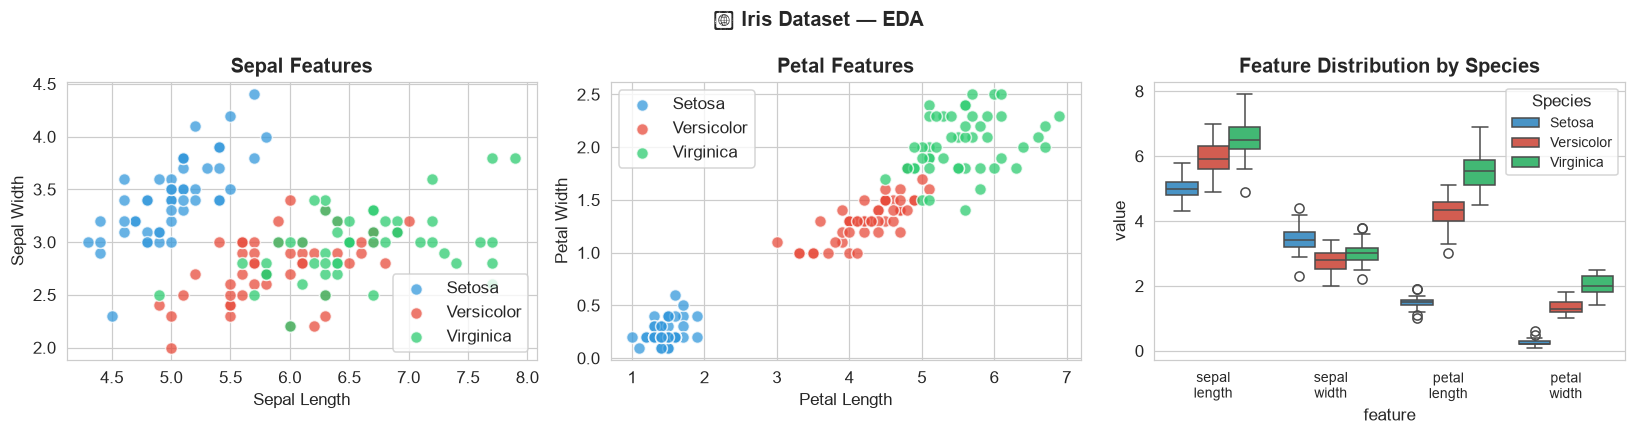

In [3]:
# B.2 Visualize Iris
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
species_colors = {'Setosa': '#3498db', 'Versicolor': '#e74c3c', 'Virginica': '#2ecc71'}

for sp, color in species_colors.items():
    subset = df_iris[df_iris['species_name'] == sp]
    axes[0].scatter(subset['sepal length (cm)'], subset['sepal width (cm)'],
                    c=color, label=sp, alpha=0.75, edgecolors='white', s=60)
    axes[1].scatter(subset['petal length (cm)'], subset['petal width (cm)'],
                    c=color, label=sp, alpha=0.75, edgecolors='white', s=60)

axes[0].set_xlabel('Sepal Length'); axes[0].set_ylabel('Sepal Width')
axes[0].set_title('Sepal Features', fontweight='bold'); axes[0].legend()

axes[1].set_xlabel('Petal Length'); axes[1].set_ylabel('Petal Width')
axes[1].set_title('Petal Features', fontweight='bold'); axes[1].legend()

# Box plot
df_melt = df_iris.melt(id_vars='species_name',
                        value_vars=iris.feature_names,
                        var_name='feature', value_name='value')
sns.boxplot(data=df_melt, x='feature', y='value', hue='species_name',
            palette=species_colors, ax=axes[2])
axes[2].set_title('Feature Distribution by Species', fontweight='bold')
axes[2].set_xticklabels(
    [f.replace('(cm)', '').strip().replace(' ', '\n') for f in iris.feature_names],
    fontsize=9
)
axes[2].legend(title='Species', fontsize=9)

plt.suptitle('🌸 Iris Dataset — EDA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [4]:
# ============================================================
# B.3 Huấn luyện Decision Tree Classifier
# ============================================================

X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris
)

# --- Huấn luyện với criterion='gini' ---
dt_clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)
dt_clf.fit(X_train_i, y_train_i)
y_pred_i = dt_clf.predict(X_test_i)

print('=== DECISION TREE CLASSIFIER — Iris ===')
print(f'Tham số: criterion=gini, max_depth=4')
print(f'Độ sâu thực tế: {dt_clf.get_depth()}')
print(f'Số lá          : {dt_clf.get_n_leaves()}')
print(f'\nAccuracy       : {accuracy_score(y_test_i, y_pred_i):.4f}')
print(f'F1-Score (macro): {f1_score(y_test_i, y_pred_i, average="macro"):.4f}')
print()
print(classification_report(y_test_i, y_pred_i, target_names=iris.target_names))


=== DECISION TREE CLASSIFIER — Iris ===
Tham số: criterion=gini, max_depth=4
Độ sâu thực tế: 4
Số lá          : 6

Accuracy       : 0.8889
F1-Score (macro): 0.8878

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45


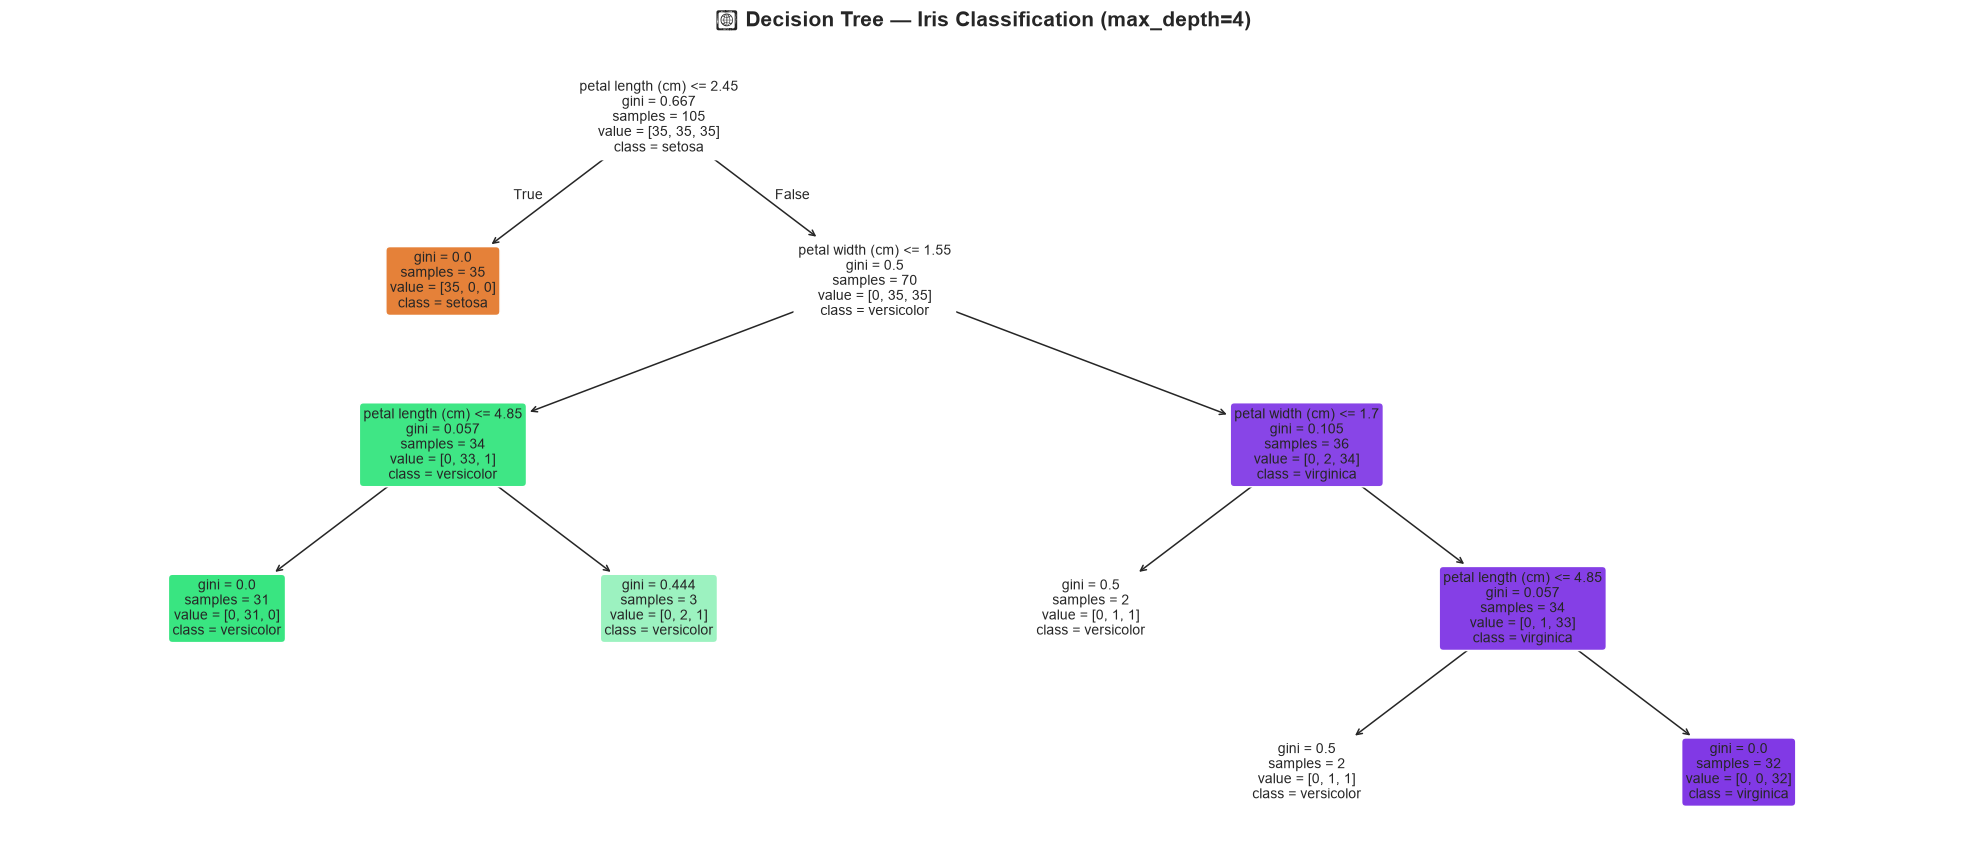

In [5]:
# B.4 Trực quan hoá cây quyết định (plot_tree)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    dt_clf,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
    impurity=True,
    proportion=False
)
ax.set_title('🌳 Decision Tree — Iris Classification (max_depth=4)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [6]:
# B.5 Text representation của cây
print('=== CẤU TRÚC CÂY (TEXT) ===')
tree_text = export_text(dt_clf,
                         feature_names=list(iris.feature_names),
                         max_depth=4)
print(tree_text)


=== CẤU TRÚC CÂY (TEXT) ===
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 1
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- petal length (cm) <= 4.85
|   |   |   |   |--- class: 1
|   |   |   |--- petal length (cm) >  4.85
|   |   |   |   |--- class: 2


Feature Importances:
  sepal length (cm)             : 0.0000
  sepal width (cm)              : 0.0000
  petal length (cm)             : 0.5482
  petal width (cm)              : 0.4518

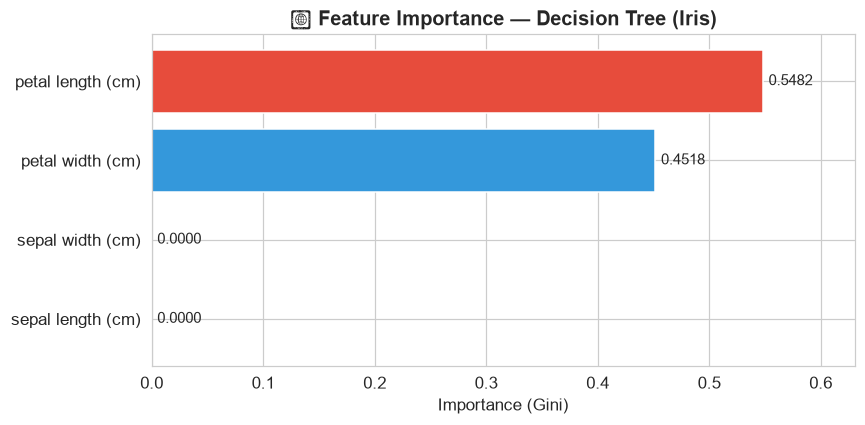

In [7]:
# B.7 Feature Importance
importances = dt_clf.feature_importances_
feat_df = pd.DataFrame({
    'Feature': iris.feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
colors_fi = ['#3498db' if v < max(importances) else '#e74c3c' for v in feat_df['Importance']]
bars = ax.barh(feat_df['Feature'], feat_df['Importance'], color=colors_fi, edgecolor='white')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2,
            f'{w:.4f}', va='center', fontsize=10)
ax.set_xlabel('Importance (Gini)')
ax.set_title('📊 Feature Importance — Decision Tree (Iris)', fontweight='bold')
ax.set_xlim(0, max(importances) * 1.15)
plt.tight_layout()
plt.show()

print('Feature Importances:')
for feat, imp in zip(iris.feature_names, importances):
    print(f'  {feat:<30}: {imp:.4f}')


---
## 🟠 Phần C — Classification: Dataset Titanic (Binary, Custom)

Dataset mô phỏng Titanic — dự đoán hành khách **sống sót** hay **không** (0/1).

Chứa: numerical + categorical + missing values → áp dụng preprocessing.


In [8]:
# ============================================================
# C.1 Tạo dataset Titanic mô phỏng
# ============================================================
np.random.seed(42)
N = 891

pclass   = np.random.choice([1, 2, 3], N, p=[0.24, 0.21, 0.55])
sex      = np.random.choice(['male', 'female'], N, p=[0.65, 0.35])
age      = np.random.normal(29.7, 14.5, N).clip(0.42, 80)
sibsp    = np.random.choice([0,1,2,3,4], N, p=[0.68,0.23,0.06,0.02,0.01])
parch    = np.random.choice([0,1,2,3],   N, p=[0.76,0.13,0.09,0.02])
fare     = np.random.exponential(32, N).clip(0, 512).round(4)
embarked = np.random.choice(['S','C','Q'], N, p=[0.72, 0.19, 0.09])

# Realistic survival probabilities
survive_prob = (
    0.35
    + 0.30 * (sex == 'female').astype(float)
    - 0.15 * (pclass == 3).astype(float)
    + 0.10 * (pclass == 1).astype(float)
    - 0.005 * age
    + np.random.uniform(-0.15, 0.15, N)
)
survived = (survive_prob > 0.35).astype(int)

df_t = pd.DataFrame({
    'Pclass'  : pclass,
    'Sex'     : sex,
    'Age'     : age,
    'SibSp'   : sibsp,
    'Parch'   : parch,
    'Fare'    : fare,
    'Embarked': embarked,
    'Survived': survived,
})

# Inject missing values
rng = np.random.default_rng(0)
df_t.loc[rng.choice(N, int(N*0.20), replace=False), 'Age'] = np.nan
df_t.loc[rng.choice(N, int(N*0.02), replace=False), 'Embarked'] = np.nan

print('=== TITANIC DATASET (Synthetic) ===')
print(f'Shape   : {df_t.shape}')
print(f'Survived: {df_t["Survived"].value_counts().to_dict()}')
print(f'Missing Age: {df_t["Age"].isna().sum()}')
print(f'Missing Embarked: {df_t["Embarked"].isna().sum()}')
df_t.head()


=== TITANIC DATASET (Synthetic) ===
Shape   : (891, 8)
Survived: {0: 606, 1: 285}
Missing Age: 178
Missing Embarked: 17
Out[0]: 
   Pclass     Sex        Age  SibSp  Parch      Fare Embarked  Survived
0       2  female  60.980969      3      0   25.1465        S         1
1       3  female  20.917134      0      0  119.0569        S         1
2       3    male        NaN      0      0   14.7413        S         0
3       3  female  34.039742      0      0   14.1411        C         1
4       1    male        NaN      0      2   13.4955        S         0

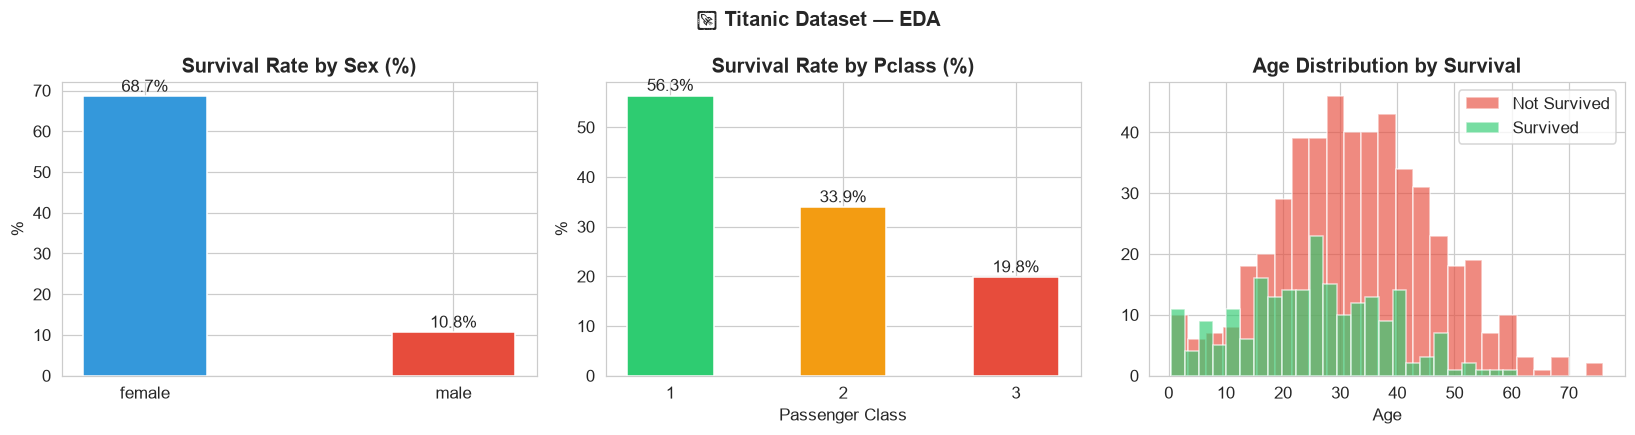

In [9]:
# C.2 EDA — Titanic
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Survival rate by Sex
surv_sex = df_t.groupby('Sex')['Survived'].mean() * 100
axes[0].bar(surv_sex.index, surv_sex.values,
            color=['#3498db', '#e74c3c'], edgecolor='white', width=0.4)
axes[0].set_title('Survival Rate by Sex (%)', fontweight='bold')
axes[0].set_ylabel('%')
for i, v in enumerate(surv_sex.values):
    axes[0].text(i, v+1, f'{v:.1f}%', ha='center')

# Survival rate by Pclass
surv_class = df_t.groupby('Pclass')['Survived'].mean() * 100
axes[1].bar(surv_class.index.astype(str), surv_class.values,
            color=['#2ecc71','#f39c12','#e74c3c'], edgecolor='white', width=0.5)
axes[1].set_title('Survival Rate by Pclass (%)', fontweight='bold')
axes[1].set_ylabel('%'); axes[1].set_xlabel('Passenger Class')
for i, v in enumerate(surv_class.values):
    axes[1].text(i, v+1, f'{v:.1f}%', ha='center')

# Age distribution by Survived
for surv, color, label in [(0,'#e74c3c','Not Survived'), (1,'#2ecc71','Survived')]:
    subset = df_t[df_t['Survived']==surv]['Age'].dropna()
    axes[2].hist(subset, bins=25, alpha=0.65, color=color, label=label, edgecolor='white')
axes[2].set_title('Age Distribution by Survival', fontweight='bold')
axes[2].set_xlabel('Age'); axes[2].legend()

plt.suptitle('🚢 Titanic Dataset — EDA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [10]:
# ============================================================
# C.3 Preprocessing & Feature Engineering
# ============================================================

df_t2 = df_t.copy()

# Feature engineering
df_t2['FamilySize'] = df_t2['SibSp'] + df_t2['Parch'] + 1
df_t2['IsAlone']    = (df_t2['FamilySize'] == 1).astype(int)
df_t2['FareBin']    = pd.qcut(df_t2['Fare'], 4, labels=[0,1,2,3]).astype(float)
df_t2['AgeBin']     = pd.cut(df_t2['Age'], bins=[0,12,18,35,60,100],
                               labels=[0,1,2,3,4]).astype(float)

# Encode Sex & Embarked
df_t2['Sex_enc'] = (df_t2['Sex'] == 'female').astype(int)
emb_imp = df_t2['Embarked'].fillna('S')
df_t2['Emb_C'] = (emb_imp == 'C').astype(int)
df_t2['Emb_Q'] = (emb_imp == 'Q').astype(int)

features = ['Pclass','Sex_enc','Fare','FamilySize','IsAlone',
            'FareBin','AgeBin','Emb_C','Emb_Q']

X_t = df_t2[features].copy()
y_t = df_t2['Survived'].values

# Impute missing Age → AgeBin via median
for col in ['AgeBin','FareBin']:
    X_t[col] = X_t[col].fillna(X_t[col].median())

X_tr_t, X_te_t, y_tr_t, y_te_t = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

print(f'Train: {X_tr_t.shape}, Test: {X_te_t.shape}')
print(f'Features: {features}')


Train: (668, 9), Test: (223, 9)
Features: ['Pclass', 'Sex_enc', 'Fare', 'FamilySize', 'IsAlone', 'FareBin', 'AgeBin', 'Emb_C', 'Emb_Q']

In [11]:
# C.4 Huấn luyện Decision Tree — Titanic
dt_titanic = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
dt_titanic.fit(X_tr_t, y_tr_t)
y_pred_t = dt_titanic.predict(X_te_t)

print('=== DECISION TREE CLASSIFIER — Titanic ===')
print(f'criterion=entropy, max_depth=5')
print(f'Độ sâu: {dt_titanic.get_depth()}  |  Số lá: {dt_titanic.get_n_leaves()}')
print()
print(f'Accuracy : {accuracy_score(y_te_t, y_pred_t):.4f}')
print(f'Precision: {precision_score(y_te_t, y_pred_t):.4f}')
print(f'Recall   : {recall_score(y_te_t, y_pred_t):.4f}')
print(f'F1-Score : {f1_score(y_te_t, y_pred_t):.4f}')
print()
print(classification_report(y_te_t, y_pred_t,
                              target_names=['Not Survived', 'Survived']))


=== DECISION TREE CLASSIFIER — Titanic ===
criterion=entropy, max_depth=5
Độ sâu: 5  |  Số lá: 20

Accuracy : 0.7937
Precision: 0.7660
Recall   : 0.5070
F1-Score : 0.6102

              precision    recall  f1-score   support

Not Survived       0.80      0.93      0.86       152
    Survived       0.77      0.51      0.61        71

    accuracy                           0.79       223
   macro avg       0.78      0.72      0.73       223
weighted avg       0.79      0.79      0.78       223


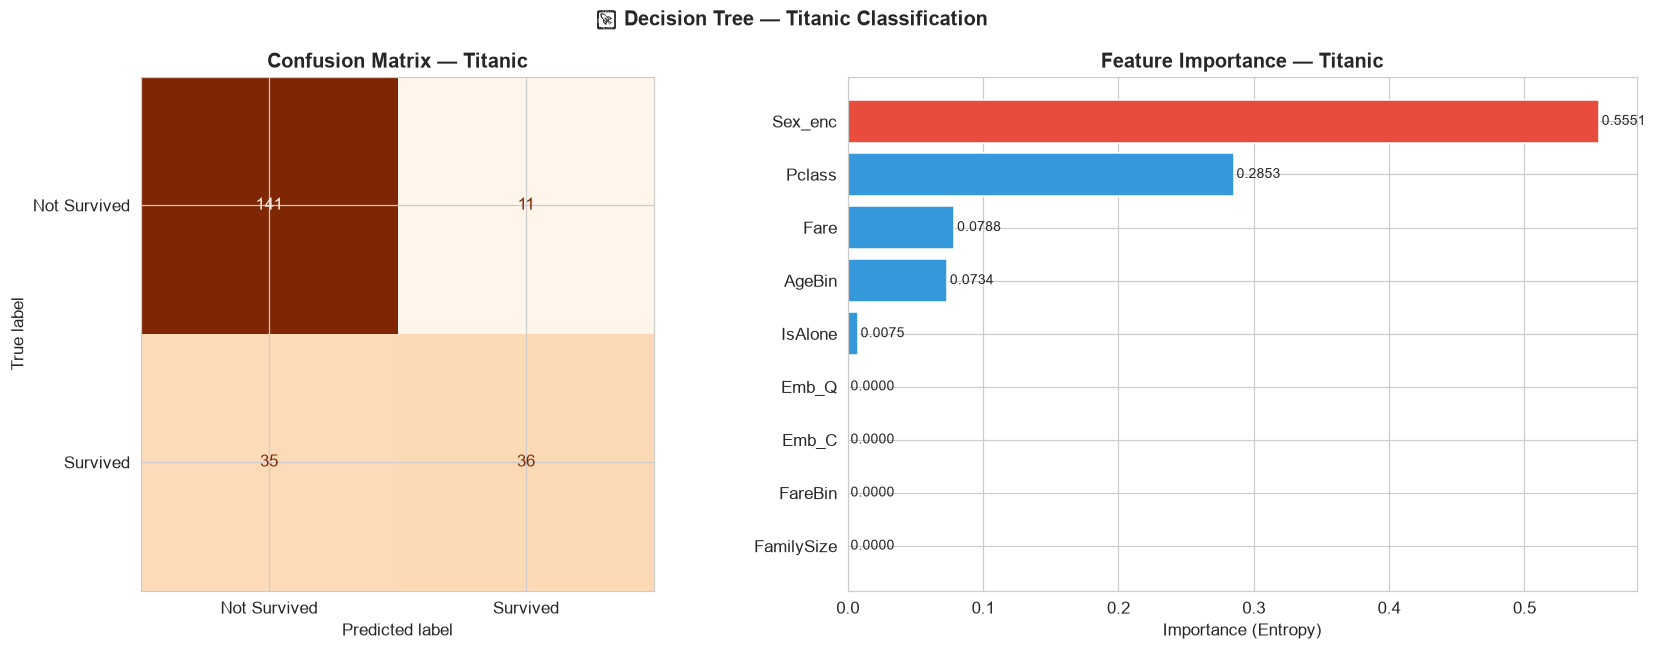

In [12]:
# C.5 Visualize cây Titanic + Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion matrix
cm_t = confusion_matrix(y_te_t, y_pred_t)
ConfusionMatrixDisplay(cm_t, display_labels=['Not Survived', 'Survived']).plot(
    ax=axes[0], cmap='Oranges', colorbar=False
)
axes[0].set_title('Confusion Matrix — Titanic', fontweight='bold')

# Feature importance
fi_t = pd.DataFrame({'Feature': features,
                      'Importance': dt_titanic.feature_importances_})\
         .sort_values('Importance', ascending=True)
colors_t = ['#e74c3c' if v == fi_t['Importance'].max() else '#3498db'
            for v in fi_t['Importance']]
axes[1].barh(fi_t['Feature'], fi_t['Importance'], color=colors_t, edgecolor='white')
for i, v in enumerate(fi_t['Importance']):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
axes[1].set_xlabel('Importance (Entropy)')
axes[1].set_title('Feature Importance — Titanic', fontweight='bold')

plt.suptitle('🚢 Decision Tree — Titanic Classification', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


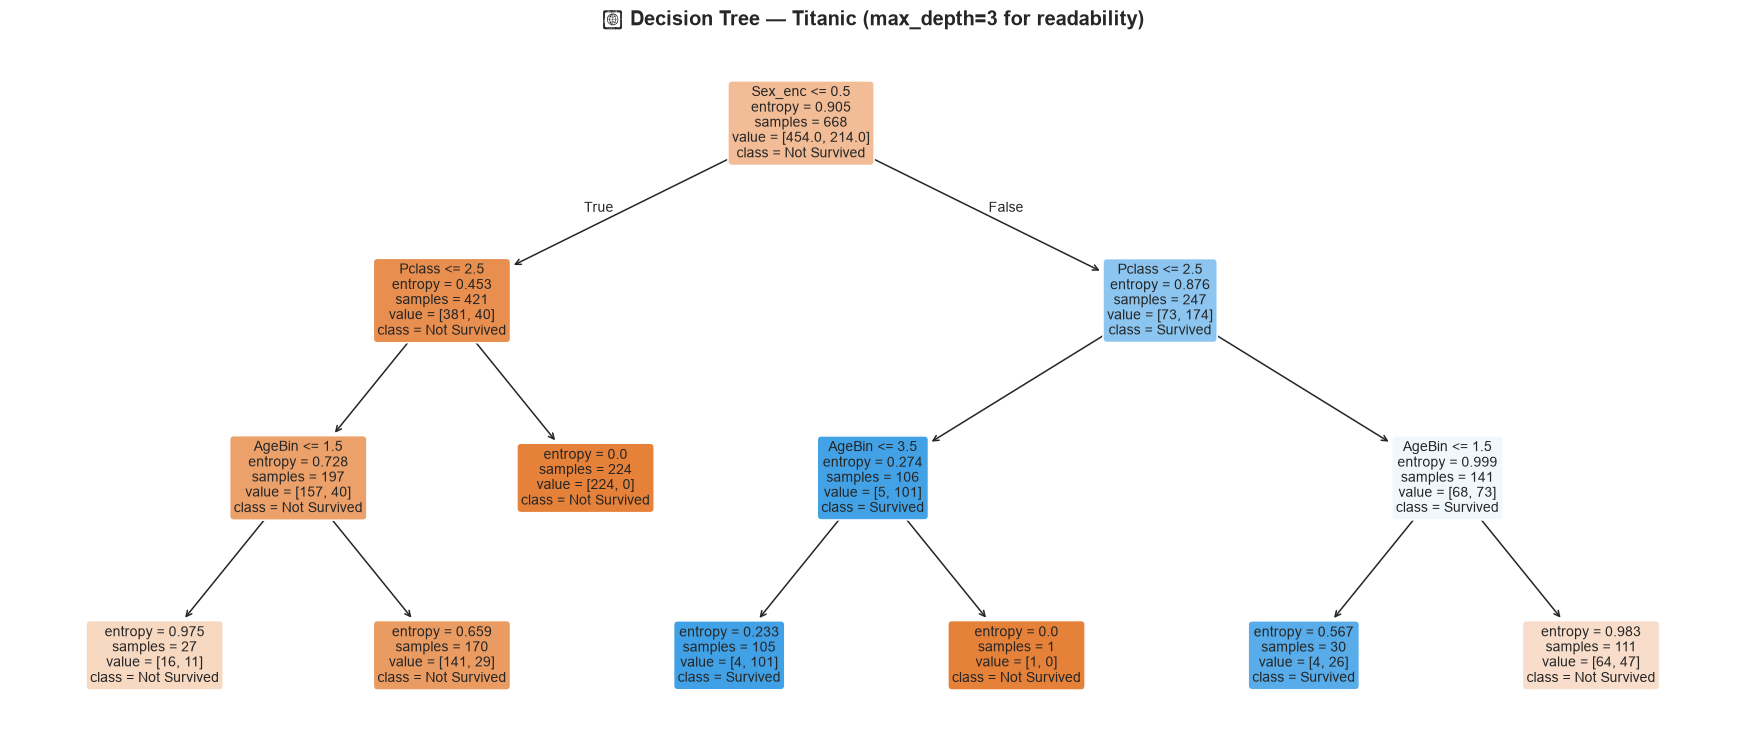

In [13]:
# C.6 Visualize cây Titanic (depth=3 để dễ đọc)
dt_titanic_vis = DecisionTreeClassifier(
    criterion='entropy', max_depth=3, random_state=42
)
dt_titanic_vis.fit(X_tr_t, y_tr_t)

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    dt_titanic_vis,
    feature_names=features,
    class_names=['Not Survived', 'Survived'],
    filled=True, rounded=True, fontsize=9, ax=ax
)
ax.set_title('🌳 Decision Tree — Titanic (max_depth=3 for readability)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 🟢 Phần D — Regression: Dự đoán giá nhà (Housing Dataset)

**Decision Tree Regressor** — dự đoán giá trị liên tục.  
Splitting criterion: **MSE** (Mean Squared Error) hoặc **MAE**.


In [14]:
# ============================================================
# D.1 Load Diabetes Dataset (regression benchmark)
#     + tạo Housing dataset mô phỏng
# ============================================================

# Tạo Housing dataset tổng hợp
np.random.seed(42)
N_h = 500

area        = np.random.uniform(40, 250, N_h)          # m²
rooms       = np.random.randint(1, 7, N_h).astype(float)
dist_center = np.random.uniform(0.5, 25, N_h)          # km
age_house   = np.random.randint(0, 50, N_h).astype(float)
floor       = np.random.randint(1, 20, N_h).astype(float)
has_garage  = np.random.choice([0, 1], N_h, p=[0.4, 0.6])
district    = np.random.choice(['A', 'B', 'C', 'D'], N_h)
district_enc = pd.get_dummies(district, prefix='dist', drop_first=False)

price = (
    500_000_000
    + 25_000_000 * area
    + 150_000_000 * rooms
    - 30_000_000 * dist_center
    - 10_000_000 * age_house
    + 20_000_000 * floor
    + 100_000_000 * has_garage
    + np.random.normal(0, 150_000_000, N_h)  # noise
).clip(500_000_000, 10_000_000_000) / 1_000_000  # in triệu VND

df_h = pd.DataFrame({
    'Area'      : area,
    'Rooms'     : rooms,
    'DistCenter': dist_center,
    'AgeHouse'  : age_house,
    'Floor'     : floor,
    'Garage'    : has_garage,
})
df_h = pd.concat([df_h, district_enc], axis=1)
df_h['Price_M'] = price

print('=== HOUSING DATASET (Synthetic — Triệu VND) ===')
print(df_h.shape)
print(df_h[['Area','Rooms','DistCenter','Price_M']].describe().round(2))
df_h.head()

=== HOUSING DATASET (Synthetic — Triệu VND) ===
(500, 11)
         Area   Rooms  DistCenter  Price_M
count  500.00  500.00      500.00   500.00
mean   144.70    3.53       13.21  4271.89
std     62.72    1.76        7.18  1654.32
min     41.06    1.00        0.51   718.34
25%     90.67    2.00        7.15  2865.16
50%    147.76    3.00       13.48  4282.24
75%    198.79    5.00       19.40  5628.64
max    248.52    6.00       24.98  7749.88
Out[0]: 
         Area  Rooms  DistCenter  AgeHouse  ...  dist_B  dist_C  dist_D      Price_M
0  118.653425    6.0   12.280506      31.0  ...    True   False   False  4262.878713
1  239.650004    1.0   23.002141      43.0  ...   False    True   False  5864.132031
2  193.718728    1.0   14.883171      17.0  ...   False   False   False  5082.722027
3  165.718282    1.0    1.304743       5.0  ...   False    True   False  4806.683469
4   72.763914    5.0   22.862362      17.0  ...   False    True   False  2584.855803

[5 rows x 11 columns]

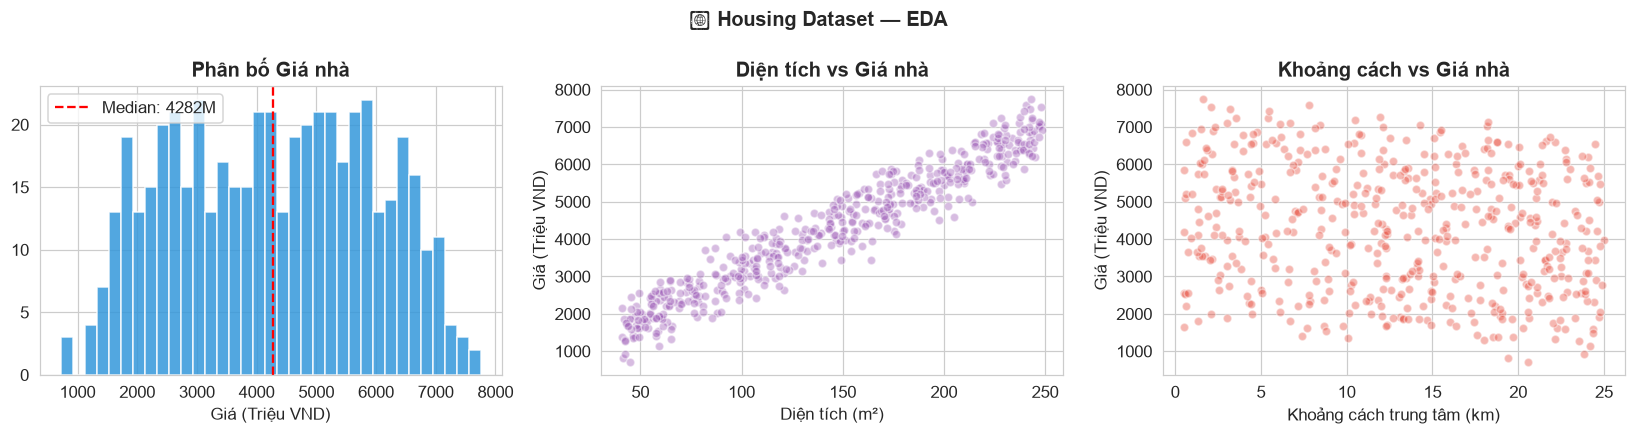

In [15]:
# D.2 EDA — Housing
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Price distribution
axes[0].hist(df_h['Price_M'], bins=35, color='#3498db', edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Giá (Triệu VND)')
axes[0].set_title('Phân bố Giá nhà', fontweight='bold')
axes[0].axvline(df_h['Price_M'].median(), color='red', linestyle='--', label=f'Median: {df_h["Price_M"].median():.0f}M')
axes[0].legend()

# Area vs Price
axes[1].scatter(df_h['Area'], df_h['Price_M'], alpha=0.4, color='#9b59b6', edgecolors='white', s=30)
axes[1].set_xlabel('Diện tích (m²)')
axes[1].set_ylabel('Giá (Triệu VND)')
axes[1].set_title('Diện tích vs Giá nhà', fontweight='bold')

# Distance vs Price
axes[2].scatter(df_h['DistCenter'], df_h['Price_M'], alpha=0.4, color='#e74c3c', edgecolors='white', s=30)
axes[2].set_xlabel('Khoảng cách trung tâm (km)')
axes[2].set_ylabel('Giá (Triệu VND)')
axes[2].set_title('Khoảng cách vs Giá nhà', fontweight='bold')

plt.suptitle('🏠 Housing Dataset — EDA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [16]:
# ============================================================
# D.3 Huấn luyện Decision Tree Regressor
# ============================================================

feat_cols_h = [c for c in df_h.columns if c != 'Price_M']
X_h = df_h[feat_cols_h].values
y_h = df_h['Price_M'].values

X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(
    X_h, y_h, test_size=0.25, random_state=42
)

# Thử nhiều max_depth
depths = [2, 3, 5, 7, 10, None]
print(f'{'max_depth':>12} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>12} {'Test MAE':>10}')
print('-' * 57)

reg_results = []
for d in depths:
    reg = DecisionTreeRegressor(
        criterion='squared_error',
        max_depth=d,
        min_samples_leaf=5,
        random_state=42
    )
    reg.fit(X_tr_h, y_tr_h)
    yp_tr = reg.predict(X_tr_h)
    yp_te = reg.predict(X_te_h)

    r2_tr = r2_score(y_tr_h, yp_tr)
    r2_te = r2_score(y_te_h, yp_te)
    rmse  = np.sqrt(mean_squared_error(y_te_h, yp_te))
    mae   = mean_absolute_error(y_te_h, yp_te)

    reg_results.append({'depth': d, 'r2_tr': r2_tr, 'r2_te': r2_te,
                        'rmse': rmse, 'mae': mae, 'model': reg})
    d_str = str(d) if d else 'None'
    print(f'{d_str:>12} {r2_tr:>10.4f} {r2_te:>10.4f} {rmse:>12.2f} {mae:>10.2f}')


   max_depth   Train R²    Test R²    Test RMSE   Test MAE
---------------------------------------------------------
           2     0.8798     0.8748       577.80     473.68
           3     0.9249     0.9122       483.97     376.09
           5     0.9708     0.9443       385.53     312.55
           7     0.9826     0.9397       400.86     332.08
          10     0.9826     0.9397       400.86     332.08
        None     0.9826     0.9397       400.86     332.08

In [17]:
# D.4 Chọn mô hình tốt nhất (best test R²)
best_reg = max(reg_results, key=lambda x: x['r2_te'])
dt_reg   = best_reg['model']
y_pred_h = dt_reg.predict(X_te_h)

print(f'=== BEST DECISION TREE REGRESSOR ===')
print(f'max_depth = {best_reg["depth"]}')
print(f'R²  (test)= {best_reg["r2_te"]:.4f}')
print(f'RMSE      = {best_reg["rmse"]:.2f} Triệu VND')
print(f'MAE       = {best_reg["mae"]:.2f} Triệu VND')


=== BEST DECISION TREE REGRESSOR ===
max_depth = 5
R²  (test)= 0.9443
RMSE      = 385.53 Triệu VND
MAE       = 312.55 Triệu VND

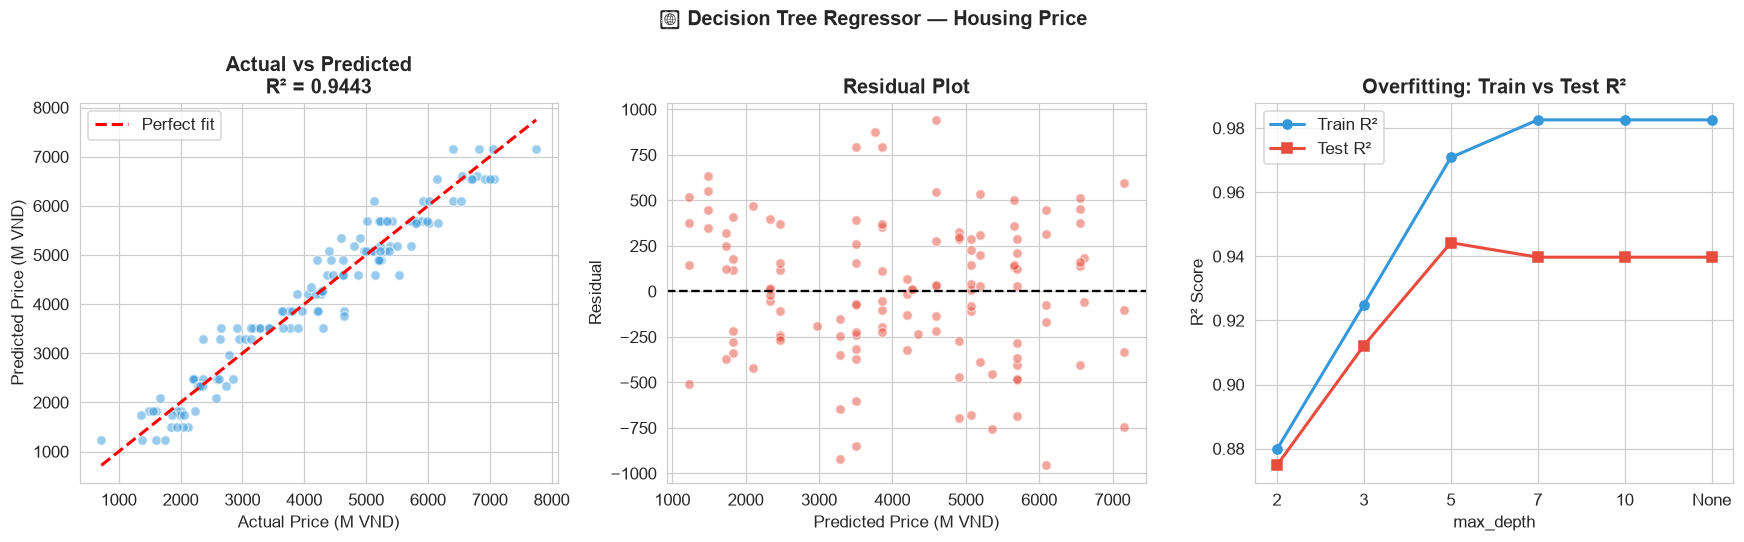

In [18]:
# D.5 Visualize Regression Results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_te_h, y_pred_h, alpha=0.5, color='#3498db', edgecolors='white', s=40)
lims = [min(y_te_h.min(), y_pred_h.min()), max(y_te_h.max(), y_pred_h.max())]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Perfect fit')
axes[0].set_xlabel('Actual Price (M VND)')
axes[0].set_ylabel('Predicted Price (M VND)')
axes[0].set_title(f'Actual vs Predicted\nR² = {best_reg["r2_te"]:.4f}', fontweight='bold')
axes[0].legend()

# 2. Residuals
residuals = y_te_h - y_pred_h
axes[1].scatter(y_pred_h, residuals, alpha=0.5, color='#e74c3c', edgecolors='white', s=40)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Predicted Price (M VND)')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual Plot', fontweight='bold')

# 3. R² vs depth (overfitting curve)
depths_plot = [str(r['depth']) if r['depth'] else 'None' for r in reg_results]
r2_tr_plot  = [r['r2_tr'] for r in reg_results]
r2_te_plot  = [r['r2_te'] for r in reg_results]
x_ax = range(len(depths_plot))
axes[2].plot(x_ax, r2_tr_plot, 'o-', color='#3498db', label='Train R²', linewidth=2)
axes[2].plot(x_ax, r2_te_plot, 's-', color='#e74c3c', label='Test R²',  linewidth=2)
axes[2].set_xticks(list(x_ax)); axes[2].set_xticklabels(depths_plot)
axes[2].set_xlabel('max_depth')
axes[2].set_ylabel('R² Score')
axes[2].set_title('Overfitting: Train vs Test R²', fontweight='bold')
axes[2].legend()

plt.suptitle('🏠 Decision Tree Regressor — Housing Price', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


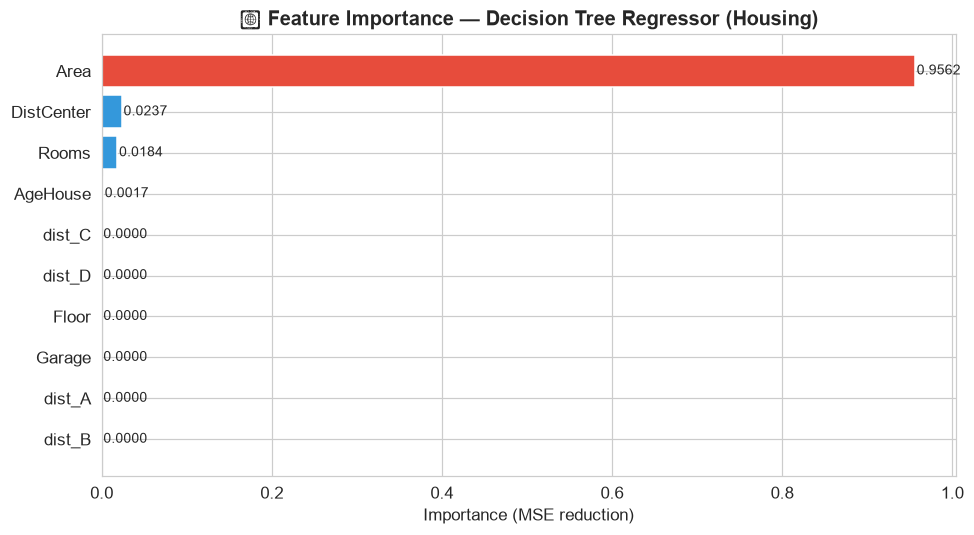

In [19]:
# D.6 Feature Importance — Regression
fi_h = pd.DataFrame({
    'Feature'   : feat_cols_h,
    'Importance': dt_reg.feature_importances_
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
colors_h = ['#e74c3c' if v == fi_h['Importance'].max() else '#3498db'
            for v in fi_h['Importance']]
bars = ax.barh(fi_h['Feature'], fi_h['Importance'], color=colors_h, edgecolor='white')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.002, bar.get_y() + bar.get_height()/2,
            f'{w:.4f}', va='center', fontsize=9)
ax.set_xlabel('Importance (MSE reduction)')
ax.set_title('📊 Feature Importance — Decision Tree Regressor (Housing)', fontweight='bold')
plt.tight_layout()
plt.show()


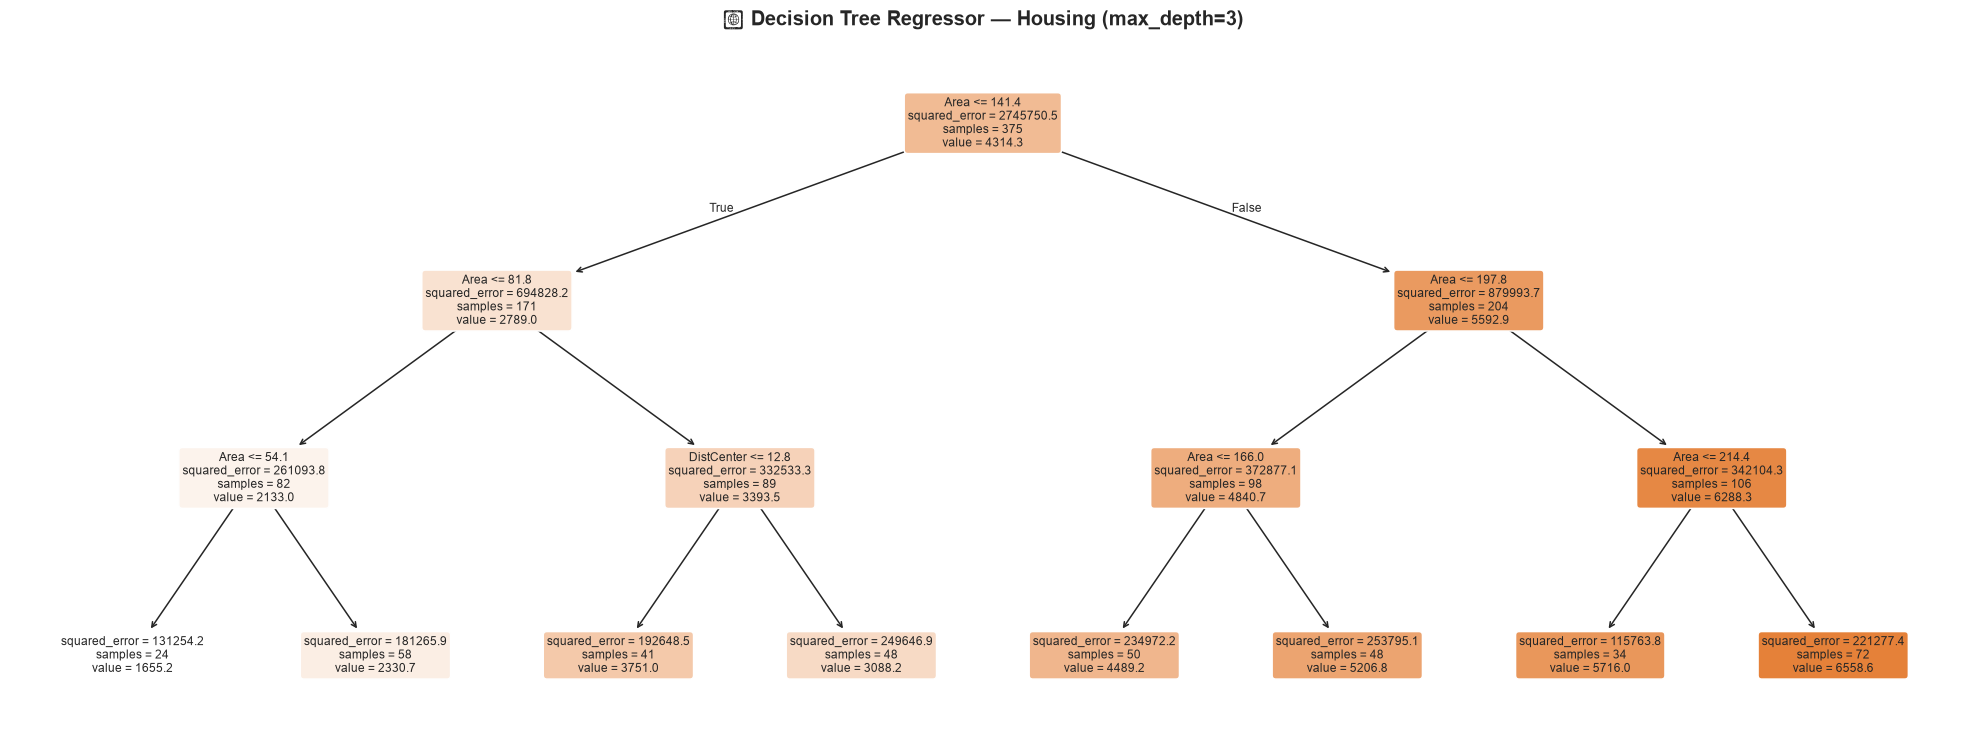

In [20]:
# D.7 Visualize cây hồi quy (depth=3)
dt_reg_vis = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_reg_vis.fit(X_tr_h, y_tr_h)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    dt_reg_vis,
    feature_names=feat_cols_h,
    filled=True, rounded=True,
    fontsize=8, ax=ax, precision=1
)
ax.set_title('🌳 Decision Tree Regressor — Housing (max_depth=3)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🔴 Phần E — Hyperparameter Tuning (GridSearchCV)


In [21]:
# ============================================================
# E.1 GridSearch cho Classification (Iris)
# ============================================================

param_grid_clf = {
    'criterion'        : ['gini', 'entropy'],
    'max_depth'        : [2, 3, 4, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 5],
}

gs_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_clf,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)
gs_clf.fit(X_train_i, y_train_i)

print('=== GRIDSEARCHCV — Decision Tree Classifier (Iris) ===')
print(f'Best params: {gs_clf.best_params_}')
print(f'Best CV F1 : {gs_clf.best_score_:.4f}')

best_clf = gs_clf.best_estimator_
y_pred_best = best_clf.predict(X_test_i)
print(f'Test Accuracy: {accuracy_score(y_test_i, y_pred_best):.4f}')
print(f'Test F1 (macro): {f1_score(y_test_i, y_pred_best, average="macro"):.4f}')


=== GRIDSEARCHCV — Decision Tree Classifier (Iris) ===
Best params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1 : 0.9522
Test Accuracy: 0.9778
Test F1 (macro): 0.9778

In [22]:
# E.2 GridSearch cho Regression (Housing)
param_grid_reg = {
    'criterion'        : ['squared_error', 'friedman_mse'],
    'max_depth'        : [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 3, 5],
}

gs_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid_reg,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
gs_reg.fit(X_tr_h, y_tr_h)

print('=== GRIDSEARCHCV — Decision Tree Regressor (Housing) ===')
print(f'Best params: {gs_reg.best_params_}')
print(f'Best CV R² : {gs_reg.best_score_:.4f}')

best_reg_gs = gs_reg.best_estimator_
y_pred_best_reg = best_reg_gs.predict(X_te_h)
print(f'Test R²  : {r2_score(y_te_h, y_pred_best_reg):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_te_h, y_pred_best_reg)):.2f} M VND')


=== GRIDSEARCHCV — Decision Tree Regressor (Housing) ===
Best params: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 2}
Best CV R² : 0.9398
Test R²  : 0.9409
Test RMSE: 396.79 M VND

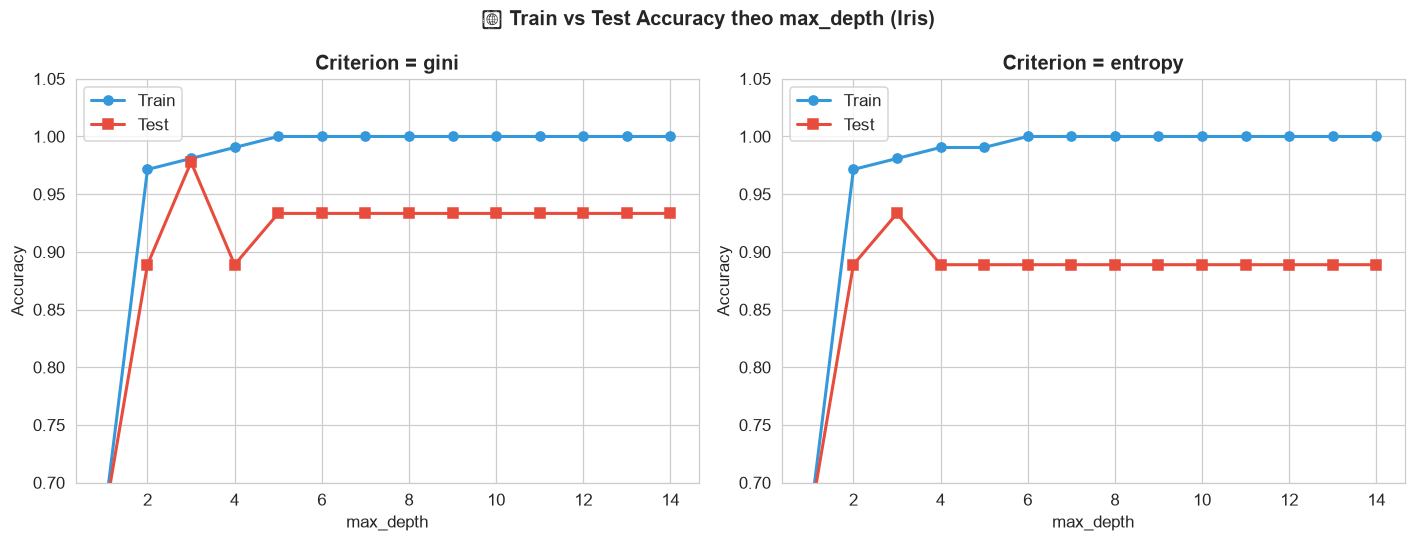

In [23]:
# E.3 Visualize Gini vs Entropy (Iris)
depths_e = range(1, 15)
results_crit = {'gini': {'train': [], 'test': []},
                'entropy': {'train': [], 'test': []}}

for crit in ['gini', 'entropy']:
    for d in depths_e:
        clf_e = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
        clf_e.fit(X_train_i, y_train_i)
        results_crit[crit]['train'].append(accuracy_score(y_train_i, clf_e.predict(X_train_i)))
        results_crit[crit]['test'].append(accuracy_score(y_test_i,  clf_e.predict(X_test_i)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax_i, crit in zip(axes, ['gini', 'entropy']):
    ax_i.plot(depths_e, results_crit[crit]['train'], 'o-',
              color='#3498db', label='Train', linewidth=2)
    ax_i.plot(depths_e, results_crit[crit]['test'],  's-',
              color='#e74c3c', label='Test',  linewidth=2)
    ax_i.set_xlabel('max_depth')
    ax_i.set_ylabel('Accuracy')
    ax_i.set_title(f'Criterion = {crit}', fontweight='bold')
    ax_i.legend()
    ax_i.set_ylim(0.7, 1.05)

plt.suptitle('📊 Train vs Test Accuracy theo max_depth (Iris)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
### E.4 Thực nghiệm: Minh chứng Overfitting & Giải quyết bằng Post-pruning (Cost-Complexity Pruning)

- **Bản chất thực nghiệm:** Khi cây phát triển tự do (`unconstrained`), cây đạt $100\%$ accuracy trên tập Train nhưng kém trên tập Test do ghi nhớ cả nhiễu.
- **Giải pháp:** Sử dụng thuật toán **Minimal Cost-Complexity Pruning** (`ccp_alpha`) của CART để cắt tỉa các nhánh lá yếu thế, tìm điểm cân bằng Bias-Variance tối ưu.

  THỰC NGHIỆM MINH CHỨNG VÀ GIẢI QUYẾT OVERFITTING
🌲 Cây chưa tỉa (Unconstrained Full Tree):
   Độ sâu: 17  |  Số lá: 131
   Train Accuracy: 1.0000 (100% học vẹt!)
   Test Accuracy : 0.7982
   Chênh lệch Overfitting (Train - Test): 20.18%

✂️ Cây sau khi Hậu tỉa cành (Cost-Complexity Pruned Tree):
   ccp_alpha tối ưu: 0.00160
   Độ sâu: 17  |  Số lá: 53
   Train Accuracy : 0.9401
   Test Accuracy  : 0.8117 (Cải thiện rõ rệt so với cây chưa tỉa!)

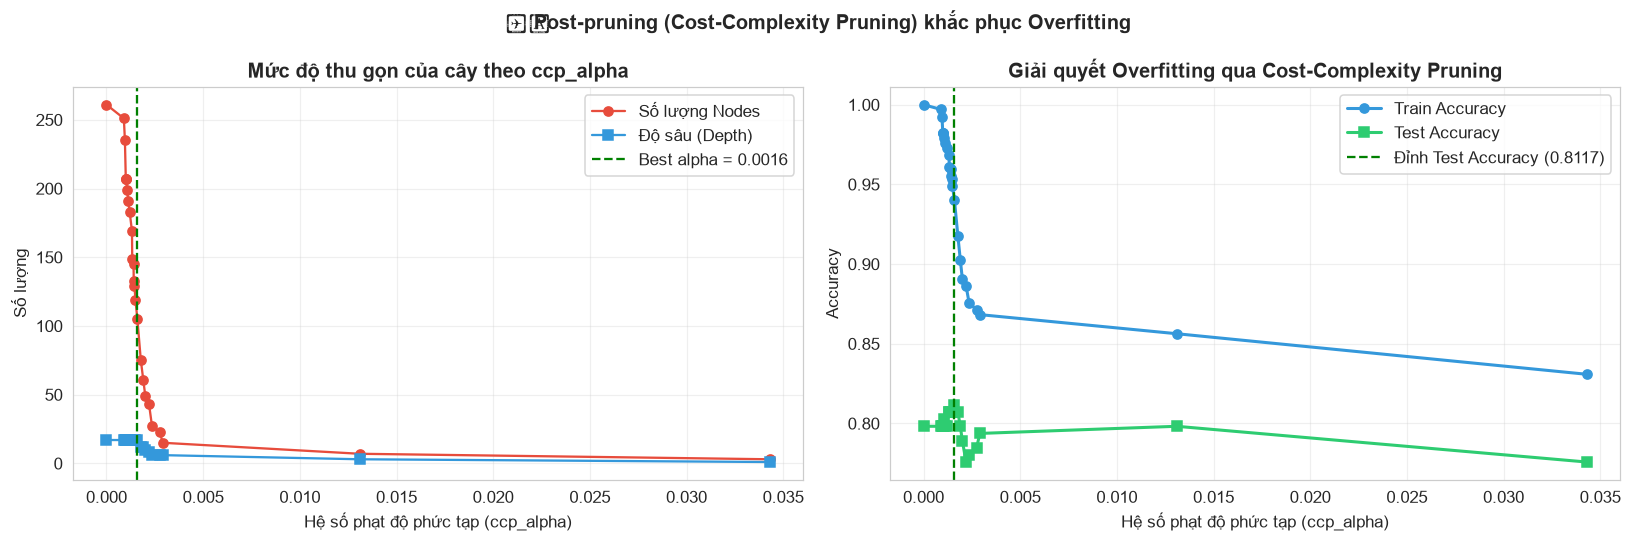

In [24]:
# ============================================================
# E.4 Thực nghiệm: Minh chứng Overfitting & Giải quyết bằng Post-pruning
#     (Cost-Complexity Pruning — ccp_alpha trên Titanic)
# ============================================================

# 1. Cây không giới hạn (Unconstrained Full Tree) -> OVERFITTING
clf_unconstrained = DecisionTreeClassifier(random_state=42)
clf_unconstrained.fit(X_tr_t, y_tr_t)

acc_train_un = accuracy_score(y_tr_t, clf_unconstrained.predict(X_tr_t))
acc_test_un  = accuracy_score(y_te_t,  clf_unconstrained.predict(X_te_t))

# 2. Tính toán đường dẫn tỉa cành (Cost-Complexity Pruning Path)
path = clf_unconstrained.cost_complexity_pruning_path(X_tr_t, y_tr_t)
ccp_alphas = path.ccp_alphas

# Lấy mẫu các giá trị alpha đại diện (loại bỏ alpha cuối cùng làm cây chỉ có 1 node)
sampled_alphas = ccp_alphas[np.linspace(0, len(ccp_alphas) - 2, 25, dtype=int)]

pruned_clfs = []
for alpha in sampled_alphas:
    clf_p = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    clf_p.fit(X_tr_t, y_tr_t)
    pruned_clfs.append(clf_p)

train_scores_p = [accuracy_score(y_tr_t, c.predict(X_tr_t)) for c in pruned_clfs]
test_scores_p  = [accuracy_score(y_te_t,  c.predict(X_te_t)) for c in pruned_clfs]
node_counts    = [c.tree_.node_count for c in pruned_clfs]
depth_counts   = [c.get_depth() for c in pruned_clfs]

best_idx = np.argmax(test_scores_p)
best_alpha = sampled_alphas[best_idx]
best_pruned_clf = pruned_clfs[best_idx]

print('=' * 65)
print('  THỰC NGHIỆM MINH CHỨNG VÀ GIẢI QUYẾT OVERFITTING')
print('=' * 65)
print(f'🌲 Cây chưa tỉa (Unconstrained Full Tree):')
print(f'   Độ sâu: {clf_unconstrained.get_depth()}  |  Số lá: {clf_unconstrained.get_n_leaves()}')
print(f'   Train Accuracy: {acc_train_un:.4f} (100% học vẹt!)')
print(f'   Test Accuracy : {acc_test_un:.4f}')
print(f'   Chênh lệch Overfitting (Train - Test): {(acc_train_un - acc_test_un)*100:.2f}%\n')
print(f'✂️ Cây sau khi Hậu tỉa cành (Cost-Complexity Pruned Tree):')
print(f'   ccp_alpha tối ưu: {best_alpha:.5f}')
print(f'   Độ sâu: {best_pruned_clf.get_depth()}  |  Số lá: {best_pruned_clf.get_n_leaves()}')
print(f'   Train Accuracy : {train_scores_p[best_idx]:.4f}')
print(f'   Test Accuracy  : {test_scores_p[best_idx]:.4f} (Cải thiện rõ rệt so với cây chưa tỉa!)')
print('=' * 65)

# Trực quan hóa quá trình tỉa cành
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Node count & Depth vs Alpha
axes[0].plot(sampled_alphas, node_counts, marker='o', label='Số lượng Nodes', color='#e74c3c')
axes[0].plot(sampled_alphas, depth_counts, marker='s', label='Độ sâu (Depth)', color='#3498db')
axes[0].set_xlabel('Hệ số phạt độ phức tạp (ccp_alpha)')
axes[0].set_ylabel('Số lượng')
axes[0].set_title('Mức độ thu gọn của cây theo ccp_alpha', fontweight='bold')
axes[0].axvline(best_alpha, color='green', linestyle='--', label=f'Best alpha = {best_alpha:.4f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Accuracy vs Alpha (Trade-off Bias - Variance)
axes[1].plot(sampled_alphas, train_scores_p, marker='o', label='Train Accuracy', color='#3498db', lw=2)
axes[1].plot(sampled_alphas, test_scores_p, marker='s', label='Test Accuracy', color='#2ecc71', lw=2)
axes[1].set_xlabel('Hệ số phạt độ phức tạp (ccp_alpha)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Giải quyết Overfitting qua Cost-Complexity Pruning', fontweight='bold')
axes[1].axvline(best_alpha, color='green', linestyle='--', label=f'Đỉnh Test Accuracy ({test_scores_p[best_idx]:.4f})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('✂️ Post-pruning (Cost-Complexity Pruning) khắc phục Overfitting', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🟣 Phần F — So sánh mô hình

So sánh **Decision Tree** với các thuật toán khác trên cả 2 bài toán.


In [25]:
# ============================================================
# F.1 So sánh Classification — Iris
# ============================================================

clf_models = {
    'Decision Tree (depth=4)'   : DecisionTreeClassifier(max_depth=4, random_state=42),
    'Decision Tree (GridSearch)': best_clf,
    'kNN (k=5)'                 : KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression'       : LogisticRegression(max_iter=500, random_state=42),
    'Random Forest'             : RandomForestClassifier(n_estimators=100, random_state=42),
}

clf_compare = []
print(f'{'Model':<30} {'Acc':>7} {'Prec':>7} {'Recall':>8} {'F1':>7}')
print('-' * 62)

for name, clf_m in clf_models.items():
    clf_m.fit(X_train_i, y_train_i)
    yp = clf_m.predict(X_test_i)
    acc  = accuracy_score(y_test_i, yp)
    prec = precision_score(y_test_i, yp, average='macro', zero_division=0)
    rec  = recall_score(y_test_i, yp, average='macro', zero_division=0)
    f1   = f1_score(y_test_i, yp, average='macro', zero_division=0)
    clf_compare.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1})
    print(f'{name:<30} {acc:>7.4f} {prec:>7.4f} {rec:>8.4f} {f1:>7.4f}')


Model                              Acc    Prec   Recall      F1
--------------------------------------------------------------
Decision Tree (depth=4)         0.8889  0.8899   0.8889  0.8888
Decision Tree (GridSearch)      0.9778  0.9792   0.9778  0.9778
kNN (k=5)                       0.9778  0.9792   0.9778  0.9778
Logistic Regression             0.9333  0.9345   0.9333  0.9333
Random Forest                   0.8889  0.8981   0.8889  0.8878

In [26]:
# F.2 So sánh Regression — Housing
reg_models = {
    'Decision Tree (depth=5)' : DecisionTreeRegressor(max_depth=5, random_state=42),
    'Decision Tree (GridSearch)': best_reg_gs,
    'Linear Regression'       : LinearRegression(),
    'kNN Regressor (k=5)'     : KNeighborsRegressor(n_neighbors=5),
    'Random Forest'           : RandomForestRegressor(n_estimators=100, random_state=42),
}

reg_compare = []
print(f'{'Model':<30} {'R²':>8} {'RMSE':>10} {'MAE':>10}')
print('-' * 62)

for name, reg_m in reg_models.items():
    reg_m.fit(X_tr_h, y_tr_h)
    yp = reg_m.predict(X_te_h)
    r2   = r2_score(y_te_h, yp)
    rmse = np.sqrt(mean_squared_error(y_te_h, yp))
    mae  = mean_absolute_error(y_te_h, yp)
    reg_compare.append({'Model': name, 'R²': r2, 'RMSE': rmse, 'MAE': mae})
    print(f'{name:<30} {r2:>8.4f} {rmse:>10.2f} {mae:>10.2f}')


Model                                R²       RMSE        MAE
--------------------------------------------------------------
Decision Tree (depth=5)          0.9372     409.21     322.69
Decision Tree (GridSearch)       0.9409     396.79     331.64
Linear Regression                0.9919     147.22     119.15
kNN Regressor (k=5)              0.9553     345.22     289.51
Random Forest                    0.9740     263.13     209.21

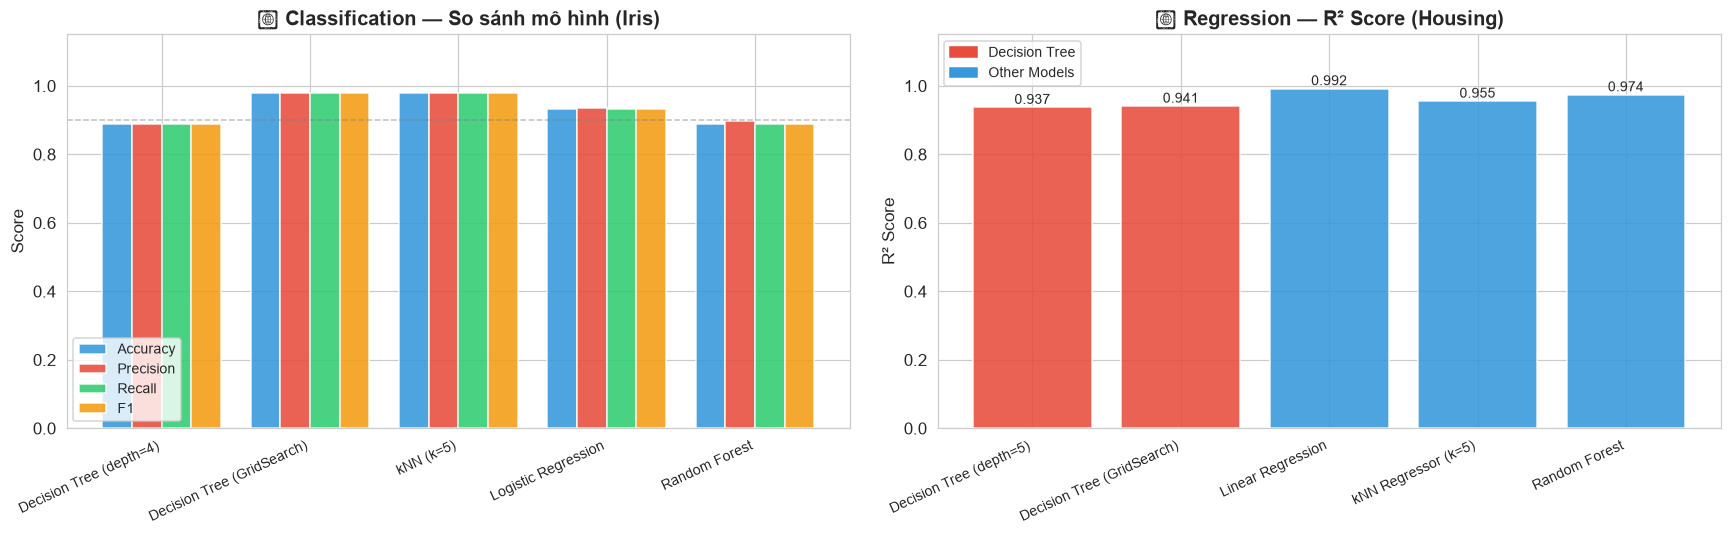

In [27]:
# F.3 Visualize So sánh
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Classification F1 ---
clf_df = pd.DataFrame(clf_compare).set_index('Model')
x_c = np.arange(len(clf_df))
w = 0.2
for i, (metric, color) in enumerate(zip(['Accuracy','Precision','Recall','F1'], COLORS)):
    axes[0].bar(x_c + i*w, clf_df[metric], width=w, label=metric,
                color=color, edgecolor='white', alpha=0.88)
axes[0].set_xticks(x_c + w*1.5)
axes[0].set_xticklabels(clf_df.index, rotation=25, ha='right', fontsize=9)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Score')
axes[0].set_title('📊 Classification — So sánh mô hình (Iris)', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].axhline(0.9, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# --- Regression R² ---
reg_df = pd.DataFrame(reg_compare).set_index('Model')
x_r = np.arange(len(reg_df))
colors_r = ['#e74c3c' if 'Decision Tree' in m else '#3498db' for m in reg_df.index]
bars_r = axes[1].bar(x_r, reg_df['R²'], color=colors_r, edgecolor='white', alpha=0.88)
for bar, v in zip(bars_r, reg_df['R²']):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.01,
                 f'{v:.3f}', ha='center', fontsize=9)
axes[1].set_xticks(x_r)
axes[1].set_xticklabels(reg_df.index, rotation=25, ha='right', fontsize=9)
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel('R² Score')
axes[1].set_title('📊 Regression — R² Score (Housing)', fontweight='bold')

dt_patch = mpatches.Patch(color='#e74c3c', label='Decision Tree')
other_patch = mpatches.Patch(color='#3498db', label='Other Models')
axes[1].legend(handles=[dt_patch, other_patch], fontsize=9)

plt.tight_layout()
plt.show()


---
## 📋 Tổng kết


In [28]:
clf_df2 = pd.DataFrame(clf_compare).set_index('Model').round(4)
reg_df2 = pd.DataFrame(reg_compare).set_index('Model').round(4)

print('=' * 65)
print('  TỔNG KẾT — Decision Tree: Classification & Regression')
print('=' * 65)
print()
print('🔵 CLASSIFICATION — Iris (3 classes, 150 mẫu)')
print(clf_df2.to_string())

best_clf_name = clf_df2['F1'].idxmax()
print(f'\n🏆 Best: {best_clf_name}  (F1={clf_df2.loc[best_clf_name,"F1"]:.4f})')

print()
print('🟢 REGRESSION — Housing (500 mẫu, Triệu VND)')
print(reg_df2.to_string())

best_reg_name = reg_df2['R²'].idxmax()
print(f'\n🏆 Best: {best_reg_name}  (R²={reg_df2.loc[best_reg_name,"R²"]:.4f})')

print()
print('📌 Nhận xét Decision Tree:')
print('  ✅ Dễ giải thích — có thể vẽ cây và đọc luật ra được')
print('  ✅ Không cần Feature Scaling')
print('  ✅ Xử lý tốt dữ liệu hỗn hợp (numerical + categorical)')
print('  ⚠  Dễ overfit → cần tuning max_depth, min_samples_leaf')
print('  ⚠  Random Forest > Decision Tree đơn lẻ trong hầu hết bài toán')
print('  💡 GridSearchCV giúp tìm hyperparameters tối ưu tự động')


  TỔNG KẾT — Decision Tree: Classification & Regression

🔵 CLASSIFICATION — Iris (3 classes, 150 mẫu)
                            Accuracy  Precision  Recall      F1
Model                                                          
Decision Tree (depth=4)       0.8889     0.8899  0.8889  0.8888
Decision Tree (GridSearch)    0.9778     0.9792  0.9778  0.9778
kNN (k=5)                     0.9778     0.9792  0.9778  0.9778
Logistic Regression           0.9333     0.9345  0.9333  0.9333
Random Forest                 0.8889     0.8981  0.8889  0.8878

🏆 Best: Decision Tree (GridSearch)  (F1=0.9778)

🟢 REGRESSION — Housing (500 mẫu, Triệu VND)
                                R²      RMSE       MAE
Model                                                 
Decision Tree (depth=5)     0.9372  409.2084  322.6894
Decision Tree (GridSearch)  0.9409  396.7935  331.6406
Linear Regression           0.9919  147.2212  119.1484
kNN Regressor (k=5)         0.9553  345.2167  289.5141
Random Forest             